# ПР-4. Линейная регрессия: собственный градиентный спуск
**Проект:** CryptoMind AI | **Выполнил:** <Баргыбаев Нуртилек cs32>

Цель: предсказать дневную доходность BTC (log_ret дня t) по признакам дней ≤ t−1.
Модель: линейная регрессия, обучаемая **вручную** методом градиентного спуска.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from src.features import CryptoFeatures

df = pd.read_csv("../data/processed/crypto_daily.csv")
btc = df[df["symbol"] == "BTCUSDT"].sort_values("open_time").reset_index(drop=True)
y = np.log(btc["close"] / btc["close"].shift(1)).iloc[1:]
X_raw = btc[["high", "low", "close", "quote_volume"]].iloc[1:]

prep = Pipeline([("features", CryptoFeatures()),
                 ("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler())])

n = len(X_raw)                       # хронологическое 80/20
Xtr = prep.fit_transform(X_raw.iloc[: int(n * 0.8)])
Xte = prep.transform(X_raw.iloc[int(n * 0.8):])
ytr = y.iloc[: int(n * 0.8)].to_numpy()
yte = y.iloc[int(n * 0.8):].to_numpy()

## 1. Математика модели
MSE: L(w) = (1/n) Σ (x_i·w − y_i)²
Градиент: ∇L(w) = (2/n) Xᵀ(Xw − y)
Шаг спуска: w ← w − η·∇L(w), где η — скорость обучения (learning rate).
Свободный член добавляем как столбец единиц.

In [3]:
def mse_loss(X, y, w):
    r = X @ w - y
    return np.mean(r ** 2)

def mse_gradient(X, y, w):
    n = len(y)
    return (2 / n) * X.T @ (X @ w - y)

def gradient_descent(X, y, lr, n_iter=3000, tol=1e-10):
    """Полный градиентный спуск (full-batch), без библиотечных оптимизаторов."""
    w = np.zeros(X.shape[1])
    history = []
    for i in range(n_iter):
        w = w - lr * mse_gradient(X, y, w)
        history.append(mse_loss(X, y, w))
        if i > 0 and abs(history[-2] - history[-1]) < tol:
            break
    return w, history

def add_bias(X):
    return np.hstack([X, np.ones((len(X), 1))])

Xtr_b, Xte_b = add_bias(Xtr), add_bias(Xte)

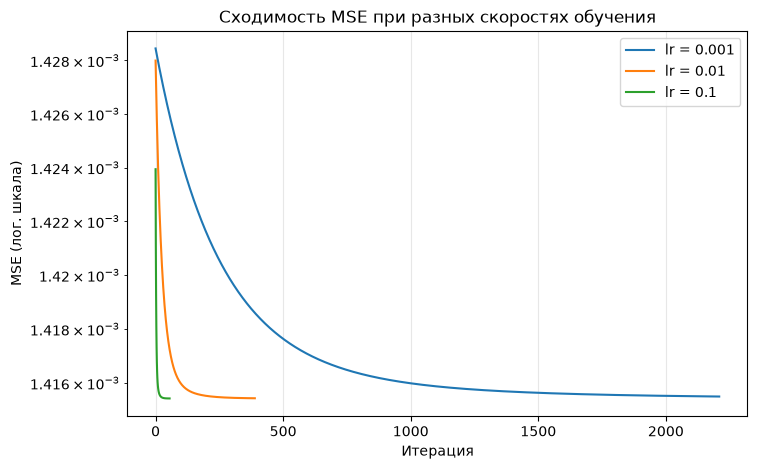

In [4]:
lrs = [0.001, 0.01, 0.1]
results = {}

plt.figure(figsize=(8, 5))
for lr in lrs:
    w, hist = gradient_descent(Xtr_b, ytr, lr=lr)
    results[lr] = (w, hist)
    plt.plot(hist, label=f"lr = {lr}")
plt.title("Сходимость MSE при разных скоростях обучения")
plt.xlabel("Итерация")
plt.ylabel("MSE (лог. шкала)")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
sk = LinearRegression().fit(Xtr, ytr)
w_ours = results[0.01][0]          # веса своего спуска при lr=0.01

print("R² на test | sklearn:", round(sk.score(Xte, yte), 5))
print("R² на test | наш GD:", round(r2_score(yte, Xte_b @ w_ours), 5))
print("Коэффициенты sklearn:", np.round(sk.coef_, 5))
print("Коэффициенты наш GD: ", np.round(w_ours[:-1], 5))
print("Свободный член  sklearn:", round(sk.intercept_, 6),
      "| наш:", round(w_ours[-1], 6))

R² на test | sklearn: -0.0087
R² на test | наш GD: -0.00859
Коэффициенты sklearn: [-0.00153  0.00199  0.00034  0.00109  0.00216 -0.00055  0.00124]
Коэффициенты наш GD:  [-0.00155  0.00198  0.00034  0.0011   0.00205 -0.00045  0.00122]
Свободный член  sklearn: 0.001183 | наш: 0.001182


## 2. Выводы
- lr = 0.001: <медленная сходимость — опиши, сколько итераций до плато>
- lr = 0.01: <рабочий режим — сходится к тому же минимуму, что и sklearn>
- lr = 0.1: <слишком большой шаг — потеря растёт/oscиллирует или сходится
  резко сначала — опиши по графику>
- Коэффициенты своего GD и sklearn совпадают до 3–4 знака — ручная реализация
  корректна. R² около нуля согласуется с гипотезой H1 (ПР-2): доходность
  близка к случайному блужданию, линейных закономерностей в этих признаках нет.